# Polymarket calibration — exploration

Working notebook behind the analysis in `README.md`. Everything here calls
the same library used by `make analyse`, so the numbers cannot disagree.

The question: when the market says 20c, does it happen 20% of the time?

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd

from src.pmcal.io import load_markets
from src.pmcal.features import prepare, FEATURE_COLUMNS
from src.pmcal import eda

pd.set_option("display.width", 110)
pd.set_option("display.max_columns", 30)

raw = load_markets("../data/raw/markets.csv")
df = prepare(raw)
print(df.attrs["cleaning_report"])
df.head()

{'rows_in': 3329, 'dropped_missing': 0, 'dropped_degenerate_price': 0, 'dropped_duplicate_market_horizon': 0, 'rows_out': 3329}


,market_id,platform,category,price,outcome,days_to_resolution,close_time,volume,logit_price,log_volume,is_longshot,is_favourite,month_index,price_x_horizon
0,253254,polymarket,unknown,0.850,1,1,2024-01-10 00:00:03+00:00,12622418.42,1.734601,16.350985,0,1,0.000000,1.202334
1,253254,polymarket,unknown,0.845,1,3,2024-01-10 00:00:03+00:00,12622418.42,1.695912,16.350985,0,1,0.000000,2.351033
2,253254,polymarket,unknown,0.880,1,7,2024-01-10 00:00:03+00:00,12622418.42,1.992430,16.350985,0,1,0.000000,4.143142
3,253254,polymarket,unknown,0.820,1,30,2024-01-10 00:00:03+00:00,12622418.42,1.516347,16.350985,0,1,0.000000,5.207118
4,253750,polymarket,unknown,0.650,1,1,2024-05-24 00:00:03+00:00,13226512.33,0.619039,16.397734,0,1,4.434954,0.429085


## 1. What is actually in here

Before any modelling: how big is the sample, how often does YES happen, and
what do the prices look like?

In [2]:
summary = eda.summary(df)
for k, v in summary.items():
    print(f"{k:28s} {v}")

n_observations               3329
n_markets                    897
observations_per_market      3.7112597547380157
horizons                     [1, 3, 7, 30]
base_rate                    0.20066085911685191
class_balance                {'yes': 668, 'no': 2661}
price                        {'mean': 0.184262901772304, 'median': 0.0055, 'q25': 0.001, 'q75': 0.285, 'min': 0.0005, 'max': 0.9995, 'share_under_5c': 0.64283568639231, 'share_over_50c': 0.1820366476419345}
date_from                    2024-01-10
date_to                      2026-08-04
categories                   {'unknown': 3329}
category_usable              False


The median price is **0.0055**. Nearly two thirds of observations are
priced under 5c.

This is the fact that shapes every later choice. A sample dominated by deep
longshots breaks equal-width binning — put these into ten uniform buckets
and the first one swallows most of the data.

In [3]:
p = df["price"]
uniform_counts = pd.cut(p, bins=np.linspace(0, 1, 11)).value_counts().sort_index()
print("equal-width bins:")
print(uniform_counts.to_string())
print()
print(f"first bin holds {uniform_counts.iloc[0] / len(p):.1%} of the sample")

equal-width bins:
price
(0.0, 0.1]    2288
(0.1, 0.2]     121
(0.2, 0.3]     104
(0.3, 0.4]      89
(0.4, 0.5]     121
(0.5, 0.6]     146
(0.6, 0.7]     136
(0.7, 0.8]      66
(0.8, 0.9]      60
(0.9, 1.0]     198

first bin holds 68.7% of the sample


In [4]:
quantile_counts = pd.qcut(p, 10, duplicates="drop").value_counts().sort_index()
print("quantile bins:")
print(quantile_counts.to_string())

quantile bins:
price
(-0.0005, 0.0015]    1248
(0.0015, 0.0025]      197
(0.0025, 0.0055]      252
(0.0055, 0.0235]      301
(0.0235, 0.13]        332
(0.13, 0.455]         336
(0.455, 0.685]        332
(0.685, 1.0]          331


Quantile bins spread the sample evenly, which is what makes a reliability
diagram readable. That is why `metrics._bin_edges` defaults to `quantile`.

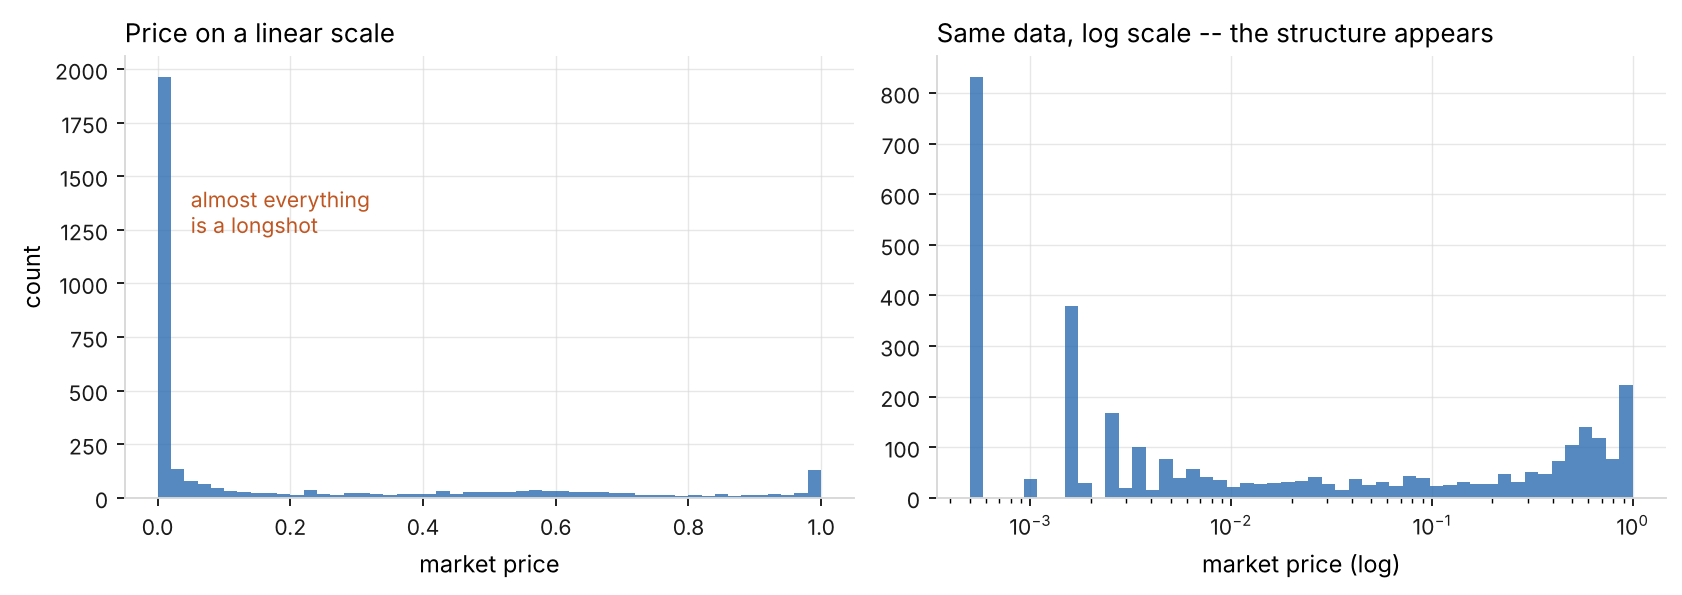

In [5]:
eda.plot_price_distribution(df, pathlib.Path("../figures/nb_price_dist.png"))
from IPython.display import Image
Image("../figures/nb_price_dist.png")

## 2. Class balance and the horizon structure

Each market appears up to four times — once per observation horizon — and
those rows share one outcome. They are **not** independent.

In [6]:
print(f"rows:    {len(df)}")
print(f"markets: {df.market_id.nunique()}")
print(f"rows per market: {len(df) / df.market_id.nunique():.2f}")
print()
print(df.groupby("market_id").size().value_counts().sort_index().to_string())

rows:    3329
markets: 897
rows per market: 3.71

1      6
2     71
3     99
4    721


In [7]:
eda.base_rate_by_horizon(df)

,days_to_resolution,n,base_rate,mean_price,median_price,price_minus_rate
0,1,885,0.212429,0.208229,0.00350,-0.004200
1,3,887,0.214205,0.206320,0.00450,-0.007886
2,7,825,0.193939,0.166581,0.00550,-0.027358
3,30,732,0.177596,0.148488,0.00925,-0.029107


Mean price exceeds the base rate at every horizon — a first hint that
contracts are, on average, priced slightly high. Whether that is real is
what the favourite-longshot test decides.

## 3. Priced versus realised

The decile view, before any statistics.

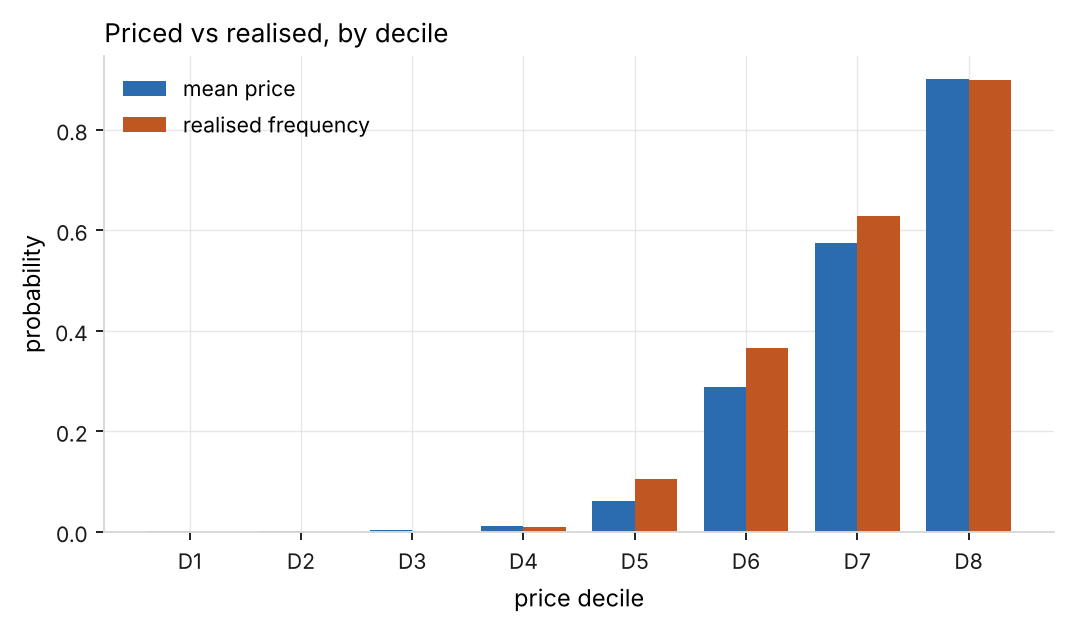

In [8]:
eda.plot_outcome_by_price_decile(df, pathlib.Path("../figures/nb_decile.png"))
Image("../figures/nb_decile.png")

## 4. Does anything correlate with the outcome besides price?

If some other feature carried real information, this is where the first sign
of it would show up.

In [9]:
corr = eda.correlations(df, FEATURE_COLUMNS)
corr["outcome"].sort_values(ascending=False)

outcome               1.000000
is_favourite          0.679149
logit_price           0.644013
price_x_horizon       0.612000
month_index           0.140719
days_to_resolution   -0.033529
log_volume           -0.082650
is_longshot          -0.651825
Name: outcome, dtype: float64

`logit_price` dominates and nothing else comes close. That is the first
evidence for the conclusion the model comparison later confirms: the price
has already absorbed whatever the other columns know.

## 5. Headline calibration at the 7-day horizon

In [10]:
from src.pmcal.metrics import (
    brier_score, brier_skill_score, cluster_bootstrap,
    murphy_decomposition, expected_calibration_error,
)

h = df[df.days_to_resolution == 7]
pp, yy, mm = (h["price"].to_numpy(float), h["outcome"].to_numpy(float),
              h["market_id"].to_numpy())

bs, lo, hi, _ = cluster_bootstrap(brier_score, pp, yy, clusters=mm, n_boot=4000)
k, klo, khi, _ = cluster_bootstrap(brier_skill_score, pp, yy, clusters=mm, n_boot=4000)
ece, mce = expected_calibration_error(pp, yy)

print(f"n              {len(h)}")
print(f"base rate      {yy.mean():.3f}")
print(f"Brier          {bs:.4f}  [{lo:.4f}, {hi:.4f}]")
print(f"Brier skill    {k:.3f}   [{klo:.3f}, {khi:.3f}]")
print(f"ECE / MCE      {ece:.4f} / {mce:.4f}")

n              825
base rate      0.194
Brier          0.0769  [0.0652, 0.0896]
Brier skill    0.508   [0.438, 0.575]
ECE / MCE      0.0321 / 0.1223


In [11]:
d = murphy_decomposition(pp, yy)
print(f"reliability  {d.reliability:.5f}   (miscalibration, lower better)")
print(f"resolution   {d.resolution:.5f}   (discrimination, higher better)")
print(f"uncertainty  {d.uncertainty:.5f}   (irreducible)")
print(f"residual     {d.residual:.2e}      (identity check on binned forecast)")

reliability  0.00309   (miscalibration, lower better)
resolution   0.08032   (discrimination, higher better)
uncertainty  0.15633   (irreducible)
residual     1.39e-17      (identity check on binned forecast)


## 6. Why the bootstrap has to cluster

The claim is that ignoring the repeated-market structure produces intervals
that are too narrow. Here is the size of that effect on the real data,
pooled across all horizons.

In [12]:
pa, ya, ma = (df["price"].to_numpy(float), df["outcome"].to_numpy(float),
              df["market_id"].to_numpy())

_, nlo, nhi, _ = cluster_bootstrap(brier_score, pa, ya, clusters=None,
                                   n_boot=3000, seed=1)
_, clo, chi, _ = cluster_bootstrap(brier_score, pa, ya, clusters=ma,
                                   n_boot=3000, seed=1)

print(f"naive   [{nlo:.5f}, {nhi:.5f}]  width {nhi-nlo:.5f}")
print(f"clustered [{clo:.5f}, {chi:.5f}]  width {chi-clo:.5f}")
print(f"\nclustered interval is {(chi-clo)/(nhi-nlo):.2f}x wider")

naive   [0.06058, 0.07133]  width 0.01076
clustered [0.05717, 0.07493]  width 0.01777

clustered interval is 1.65x wider


Narrower intervals are not a better result — they are a false one. Every
confidence statement in this project uses the clustered version.

## 7. The favourite-longshot test

In [13]:
from src.pmcal.calibration import favourite_longshot_test, reliability_bins

flb = favourite_longshot_test(pp, yy, clusters=mm)
print(f"slope      {flb.slope:.3f}  [{flb.slope_lo:.3f}, {flb.slope_hi:.3f}]")
print(f"intercept  {flb.intercept:.3f}")
print(f"p(slope=1) {flb.p_value_slope_eq_1:.4f}")
print(f"differs from 1: {flb.slope_differs_from_one}")

slope      0.867  [0.754, 0.980]
intercept  0.338
p(slope=1) 0.0206
differs from 1: True


In [14]:
reliability_bins(pp, yy)

,bin,lo_edge,hi_edge,n,mean_price,realised_freq,wilson_lo,wilson_hi,gap
0,0,0.0000,0.0015,297,0.000857,0.000000,0.000000,0.012769,0.000857
1,1,0.0015,0.0025,56,0.002464,0.000000,0.000000,0.064194,0.002464
2,2,0.0025,0.0055,63,0.004063,0.000000,0.000000,0.057471,0.004063
3,3,0.0055,0.0229,79,0.011158,0.012658,0.002238,0.068276,-0.001500
4,4,0.0229,0.1000,83,0.053657,0.156627,0.093880,0.249751,-0.102970
5,5,0.1000,0.3860,82,0.231335,0.353659,0.258856,0.461559,-0.122323
6,6,0.3860,0.6510,82,0.526201,0.597561,0.489365,0.697026,-0.071360
7,7,0.6510,1.0000,83,0.835277,0.819277,0.723001,0.887306,0.016000


A slope below 1 means the realised curve is flatter than the diagonal.
The bin table localises it: mid-probability contracts resolve YES more often
than they are priced.

The published study this dataset came from reported a slope of 1.01 and
found no bias. This analysis clusters the standard errors and restricts to a
single horizon, and gets an interval that excludes 1. That disagreement is
documented in the README rather than smoothed over.

## 8. Where this goes next

The backtest, the threshold sweep and the model comparison all live in
`src/pmcal/` and run together via `make analyse`. The short version: the
bias is real but small, and it does not survive transaction costs — every
net-return interval crosses zero.